1 ЗАДАНИЕ Для изображения sar_3.jpg найти наиболее протяженный участок (выделить линии при помощи преобразования Хафа)

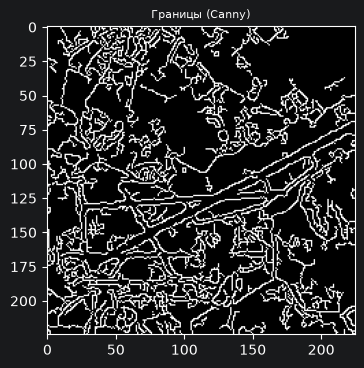

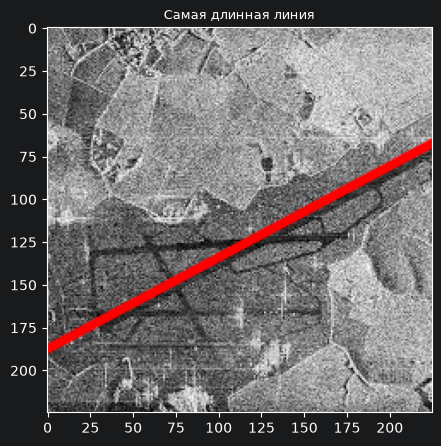

In [1]:
import cv2
import numpy as np
import math
import copy
import matplotlib.pyplot as plt

image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

#1 часть


blurred = cv2.GaussianBlur(image_gray, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150, apertureSize=3)

plt.figure(figsize=(5, 4))
plt.title("Границы (Canny)", fontsize=8)
plt.imshow(edges, cmap='gray')
plt.show()

lines = cv2.HoughLines(edges, 1, np.pi / 180, 60)

ys, xs = np.where(edges > 0)

best = None
mx = 0

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        cos_t, sin_t = math.cos(theta), math.sin(theta)
        d = np.abs(xs * cos_t + ys * sin_t - rho)
        cnt = int((d < 1.0).sum())
        if cnt > mx:
            mx = cnt
            best = (rho, theta)


image_lines = copy.deepcopy(image)

if best is not None:
    rho, theta = best
    a, b = math.cos(theta), math.sin(theta)
    x0, y0 = a * rho, b * rho
    pt1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
    pt2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
    cv2.line(image_lines, pt1, pt2, (0, 0, 255), 3, cv2.LINE_AA)



plt.figure(figsize=(6, 5))
plt.title("Самая длинная линия", fontsize=9)
plt.imshow(cv2.cvtColor(image_lines, cv2.COLOR_BGR2RGB))
plt.show()

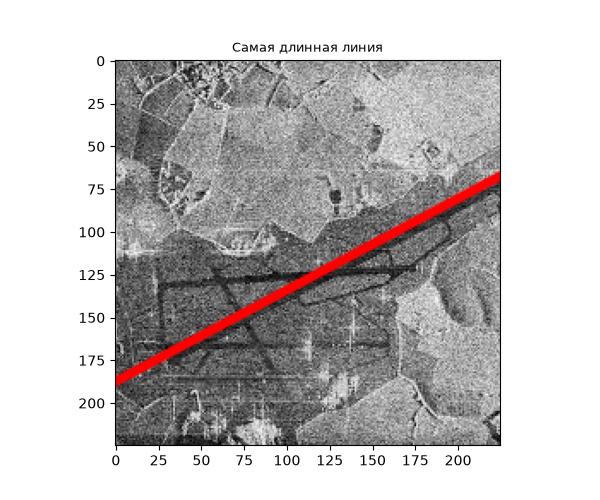

2 ЗАДАНИЕ Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

In [2]:
_, bin_manual_50  = cv2.threshold(image_gray, 50,  255, cv2.THRESH_BINARY)
_, bin_manual_100 = cv2.threshold(image_gray, 100, 255, cv2.THRESH_BINARY)
_, bin_manual_150 = cv2.threshold(image_gray, 150, 255, cv2.THRESH_BINARY)

_, bin_otsu = cv2.threshold(image_gray, 0, 255,
                            cv2.THRESH_BINARY + cv2.THRESH_OTSU)

bin_adaptive = cv2.adaptiveThreshold(
    image_gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 71, 21
)



Бинаризация

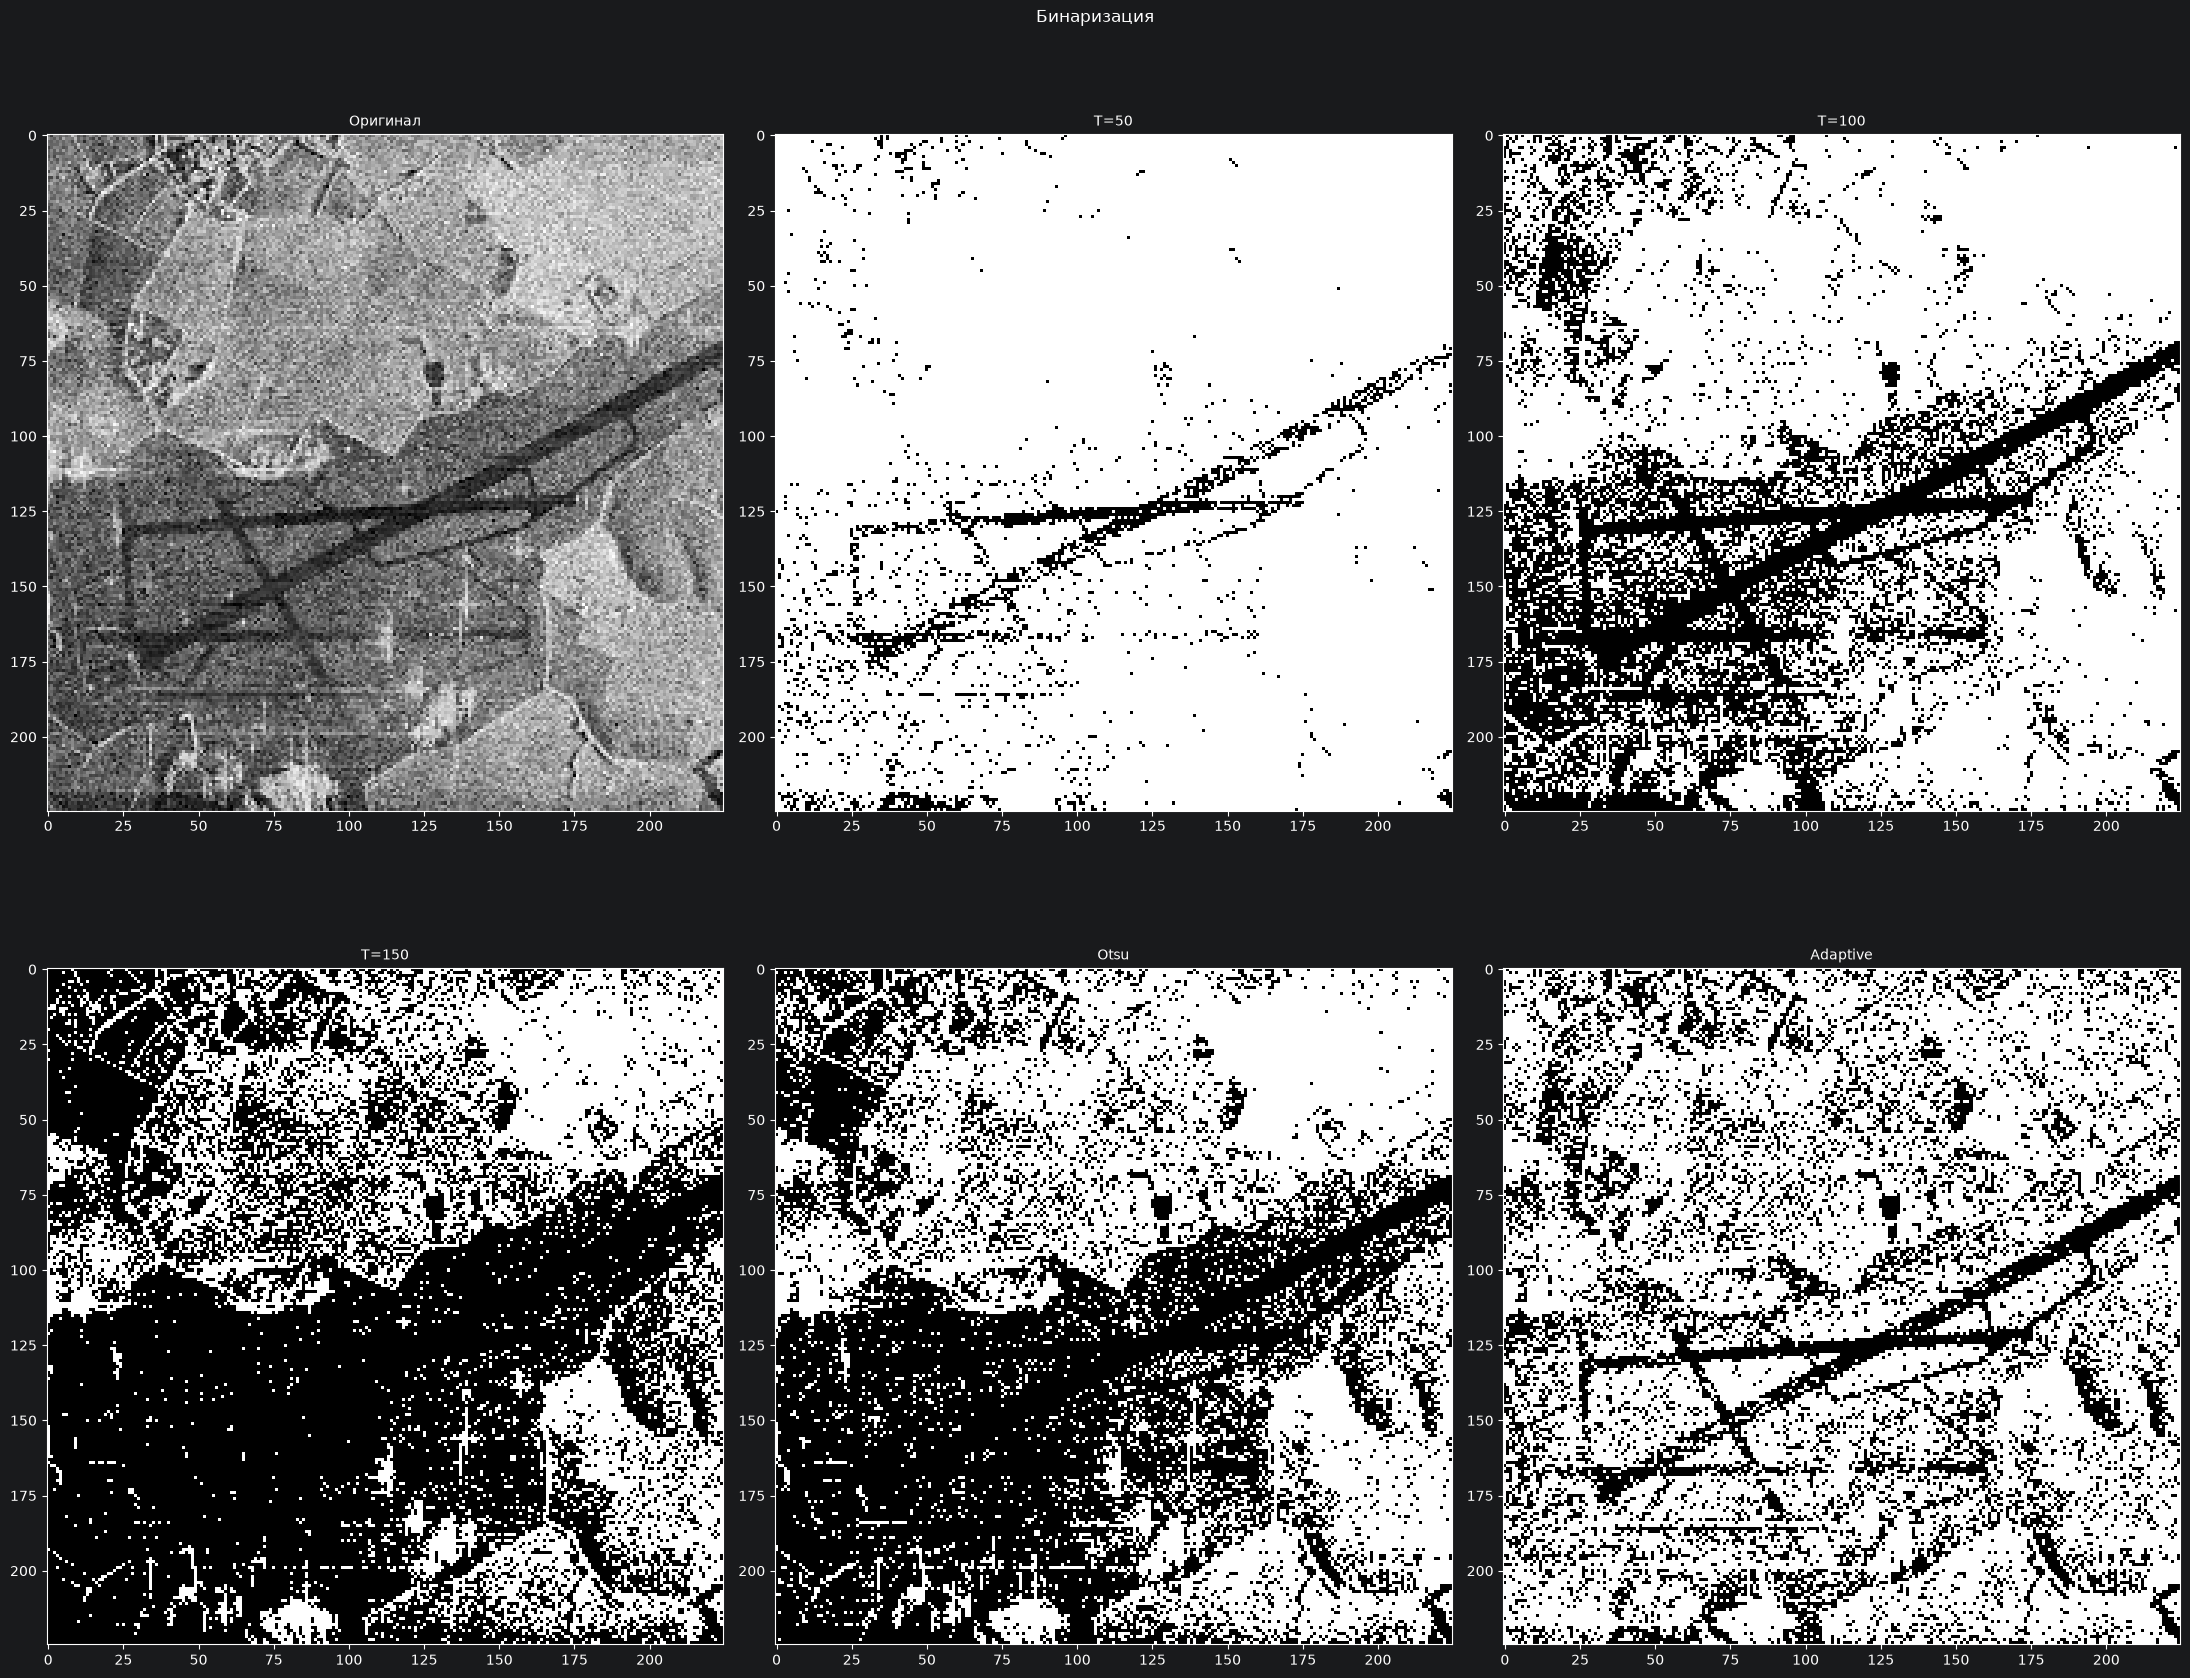

In [3]:
plt.figure(figsize=(22, 18))
plt.suptitle("Бинаризация", fontsize=12)


plt.subplot(2, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title("Оригинал", fontsize=10)

plt.subplot(2, 3, 2)
plt.imshow(bin_manual_50, cmap='gray')
plt.title("T=50", fontsize=10)

plt.subplot(2, 3, 3)
plt.imshow(bin_manual_100, cmap='gray')
plt.title("T=100", fontsize=10)

plt.subplot(2, 3, 4)
plt.imshow(bin_manual_150, cmap='gray')
plt.title("T=150", fontsize=10)

plt.subplot(2, 3, 5)
plt.imshow(bin_otsu, cmap='gray')
plt.title("Otsu", fontsize=10)

plt.subplot(2, 3, 6)
plt.imshow(bin_adaptive, cmap='gray')
plt.title("Adaptive", fontsize=10)

plt.tight_layout()
plt.show()

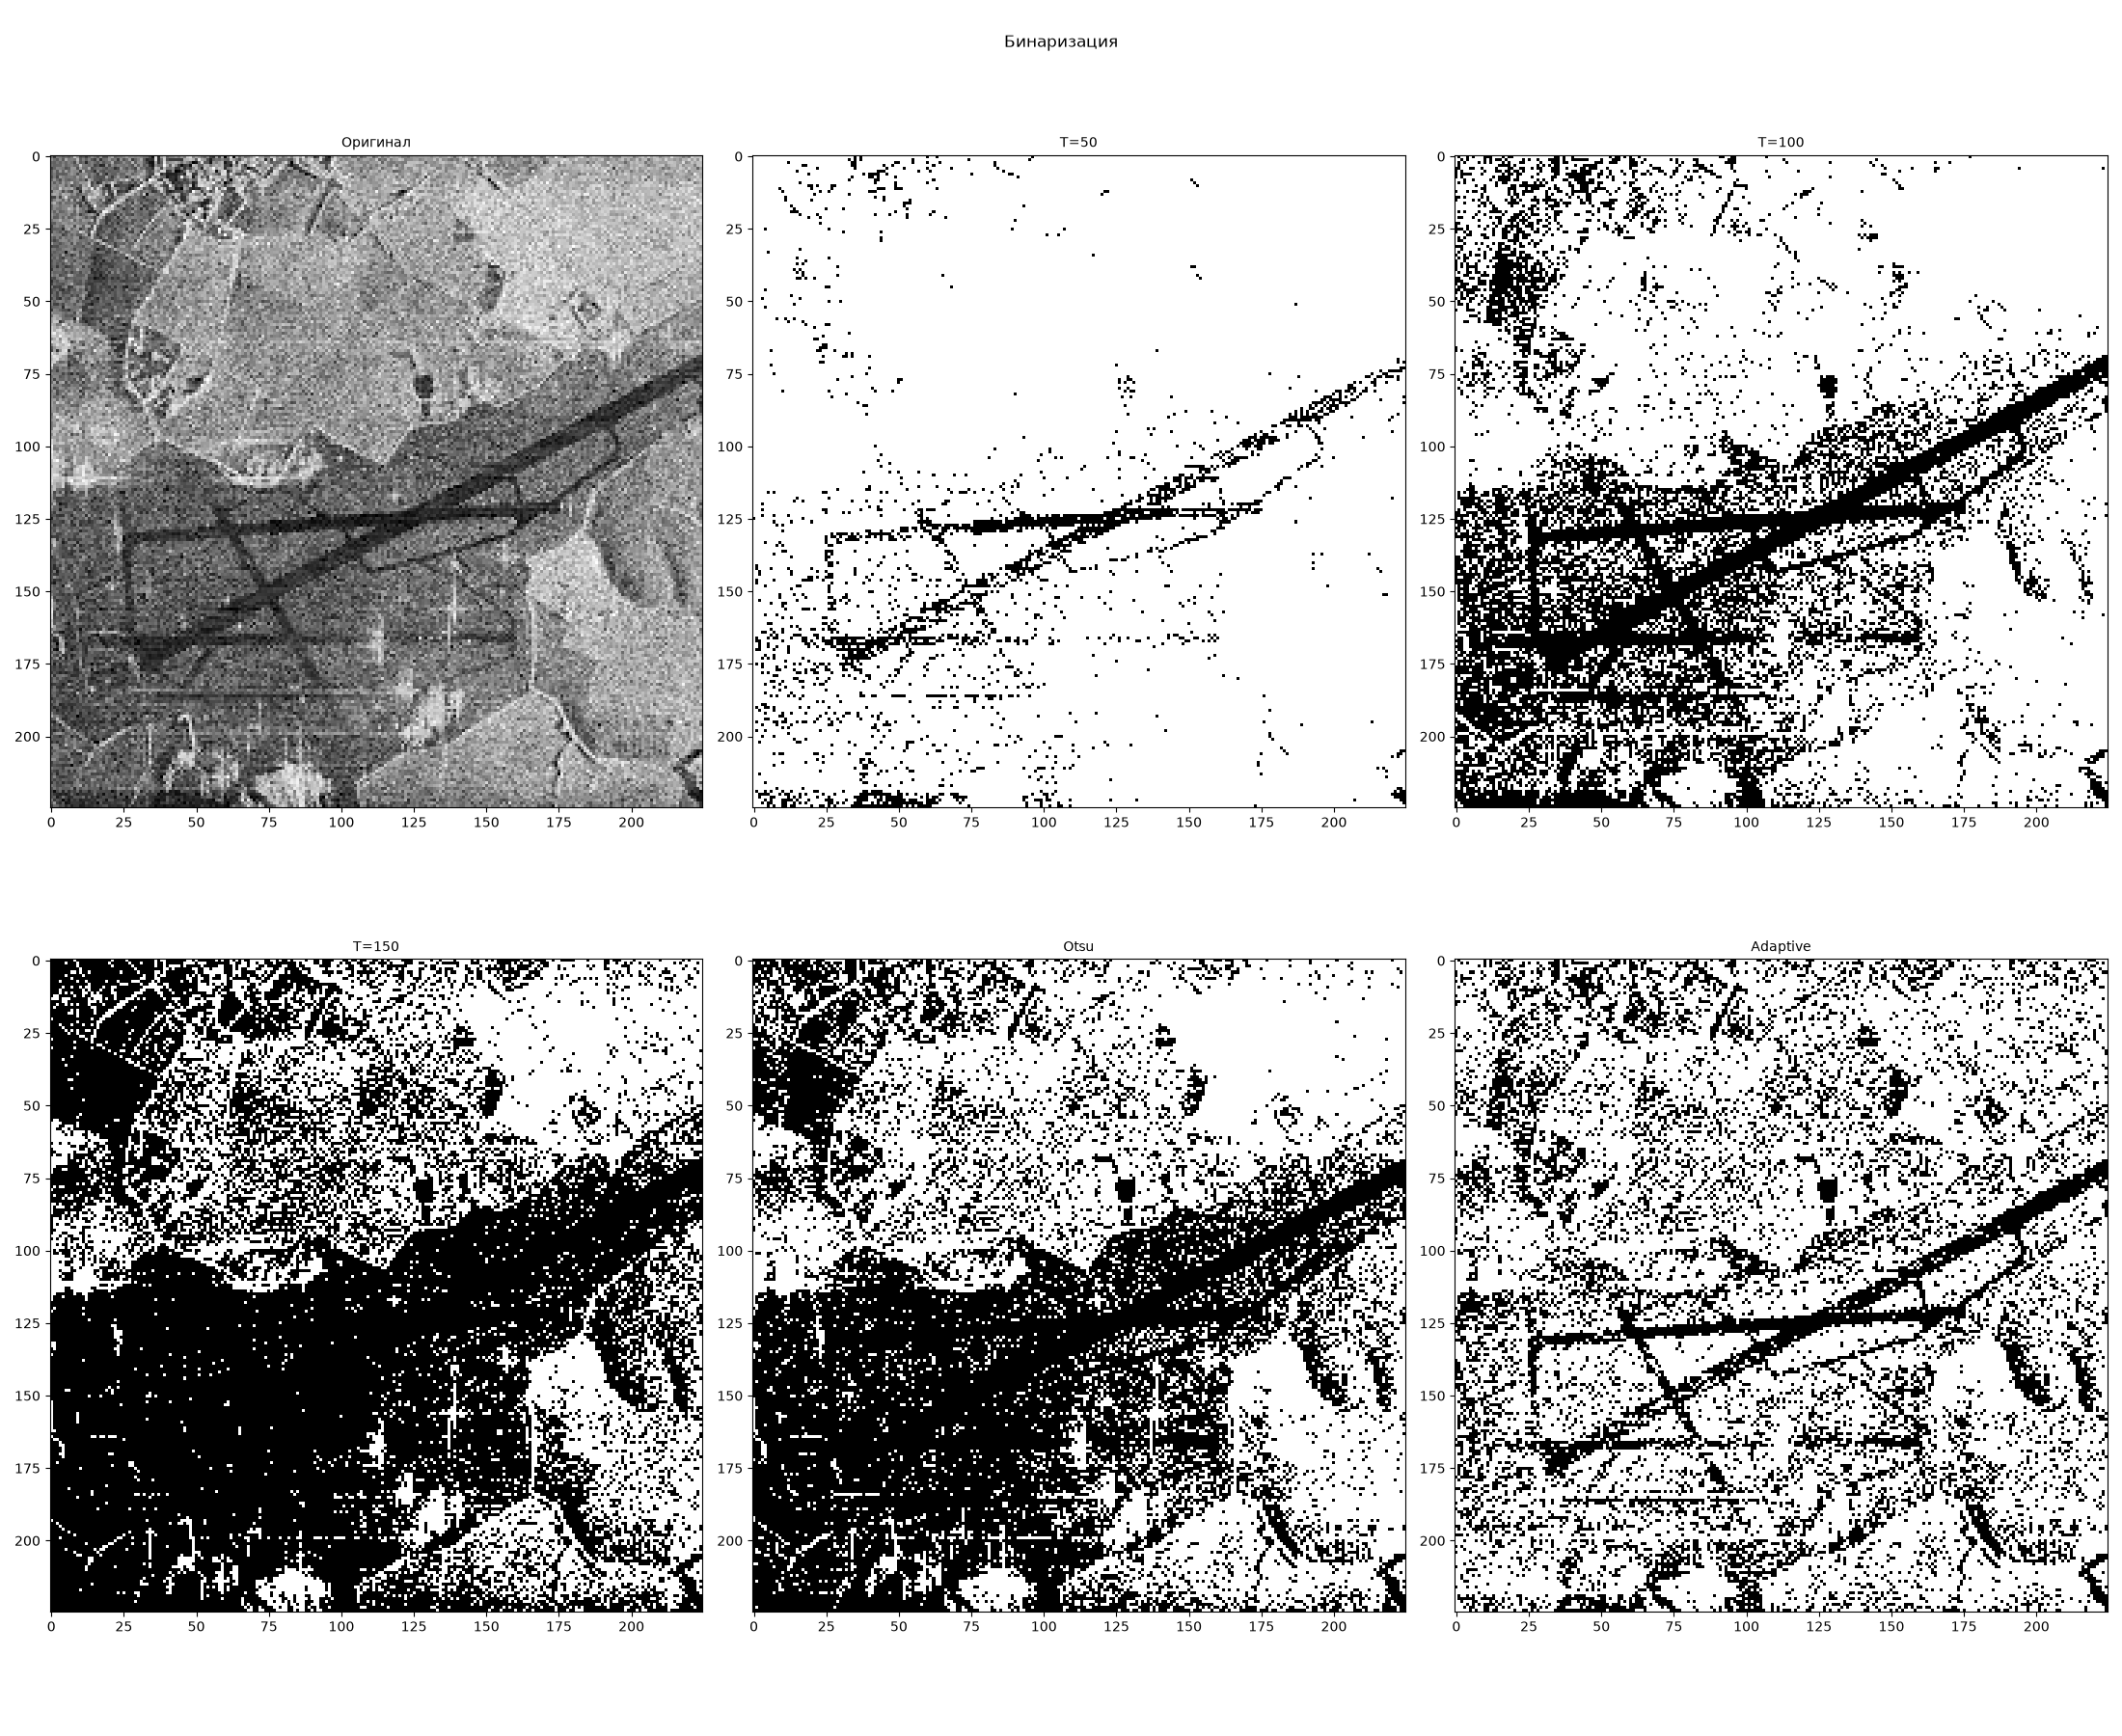

Выделение

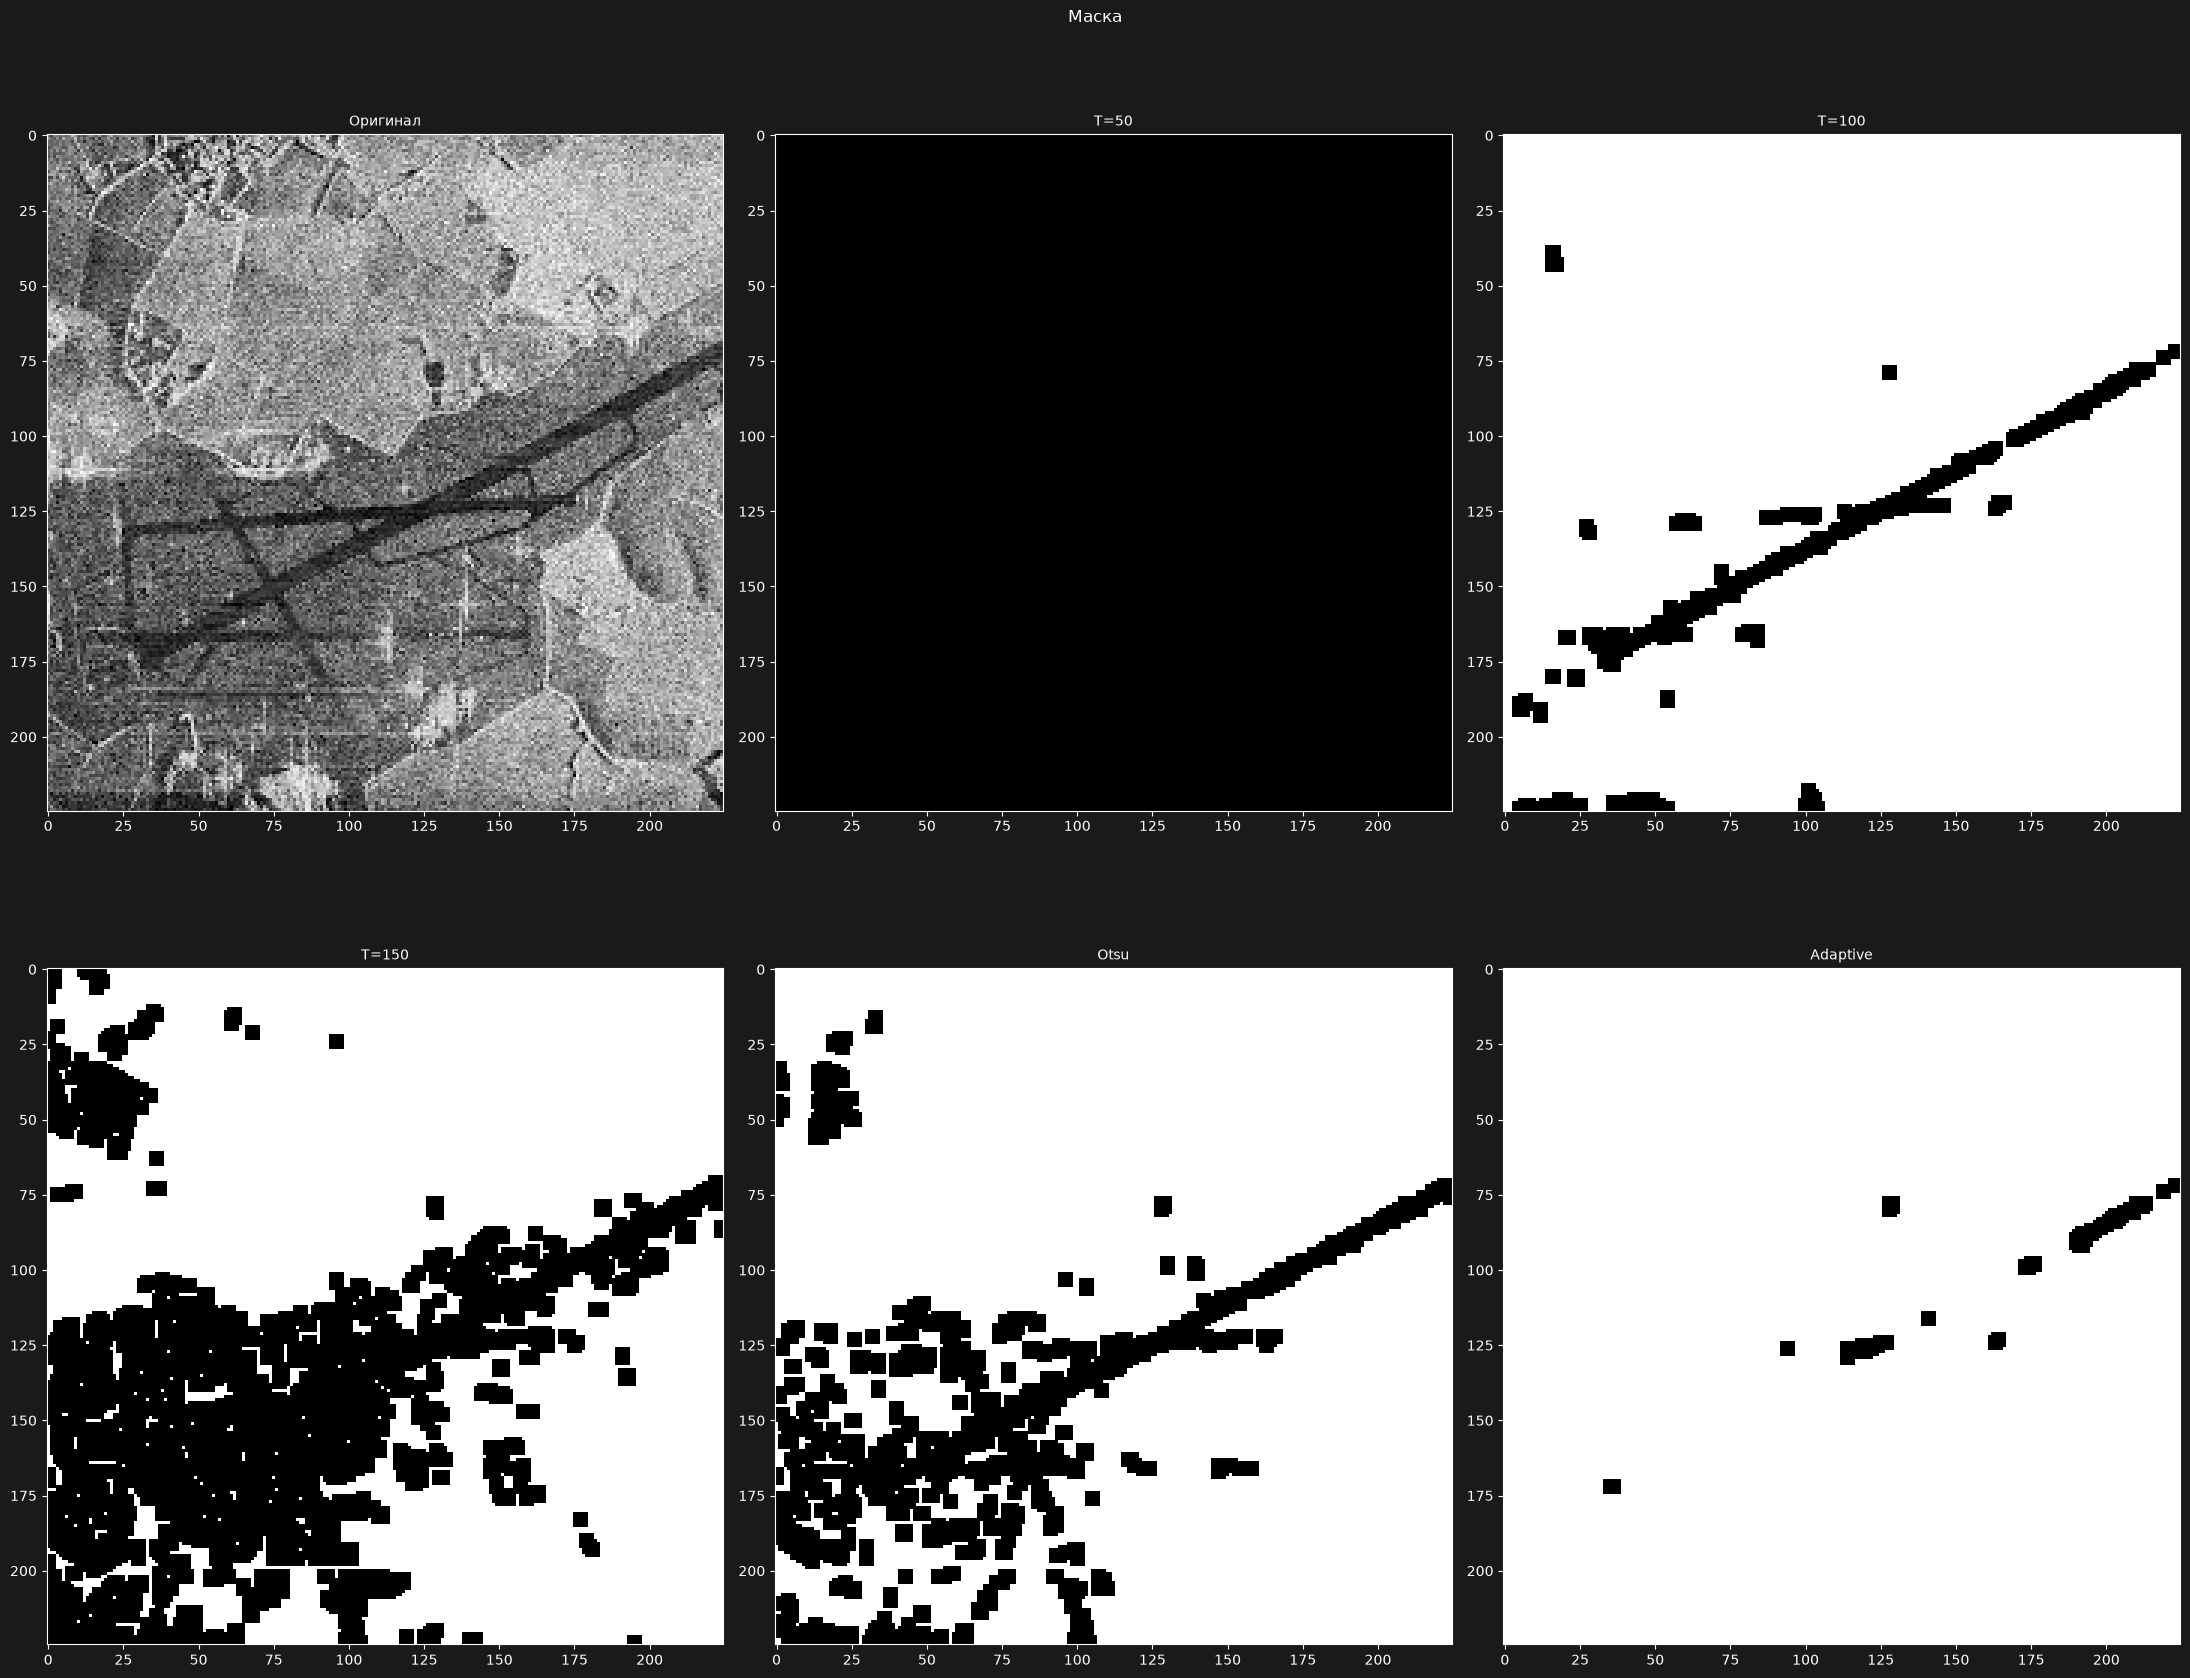

In [4]:
k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

plt.figure(figsize=(22, 18))
plt.suptitle("Маска", fontsize=12)


plt.subplot(2, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title("Оригинал", fontsize=10)

segm_50 = cv2.morphologyEx(bin_manual_50, cv2.MORPH_CLOSE, k)
plt.subplot(2, 3, 2)
plt.imshow(segm_50, cmap='bone')
plt.title("T=50", fontsize=10)

segm_100 = cv2.morphologyEx(bin_manual_100, cv2.MORPH_CLOSE, k)
plt.subplot(2, 3, 3)
plt.imshow(segm_100, cmap='bone')
plt.title("T=100", fontsize=10)

segm_150 = cv2.morphologyEx(bin_manual_150, cv2.MORPH_CLOSE, k)
plt.subplot(2, 3, 4)
plt.imshow(segm_150, cmap='bone')
plt.title("T=150", fontsize=10)

segm_otsu = cv2.morphologyEx(bin_otsu, cv2.MORPH_CLOSE, k)
plt.subplot(2, 3, 5)
plt.imshow(segm_otsu, cmap='bone')
plt.title("Otsu", fontsize=10)

segm_adapt = cv2.morphologyEx(bin_adaptive, cv2.MORPH_CLOSE, k)
plt.subplot(2, 3, 6)
plt.imshow(segm_adapt, cmap='bone')
plt.title("Adaptive", fontsize=10)

plt.tight_layout()
plt.show()

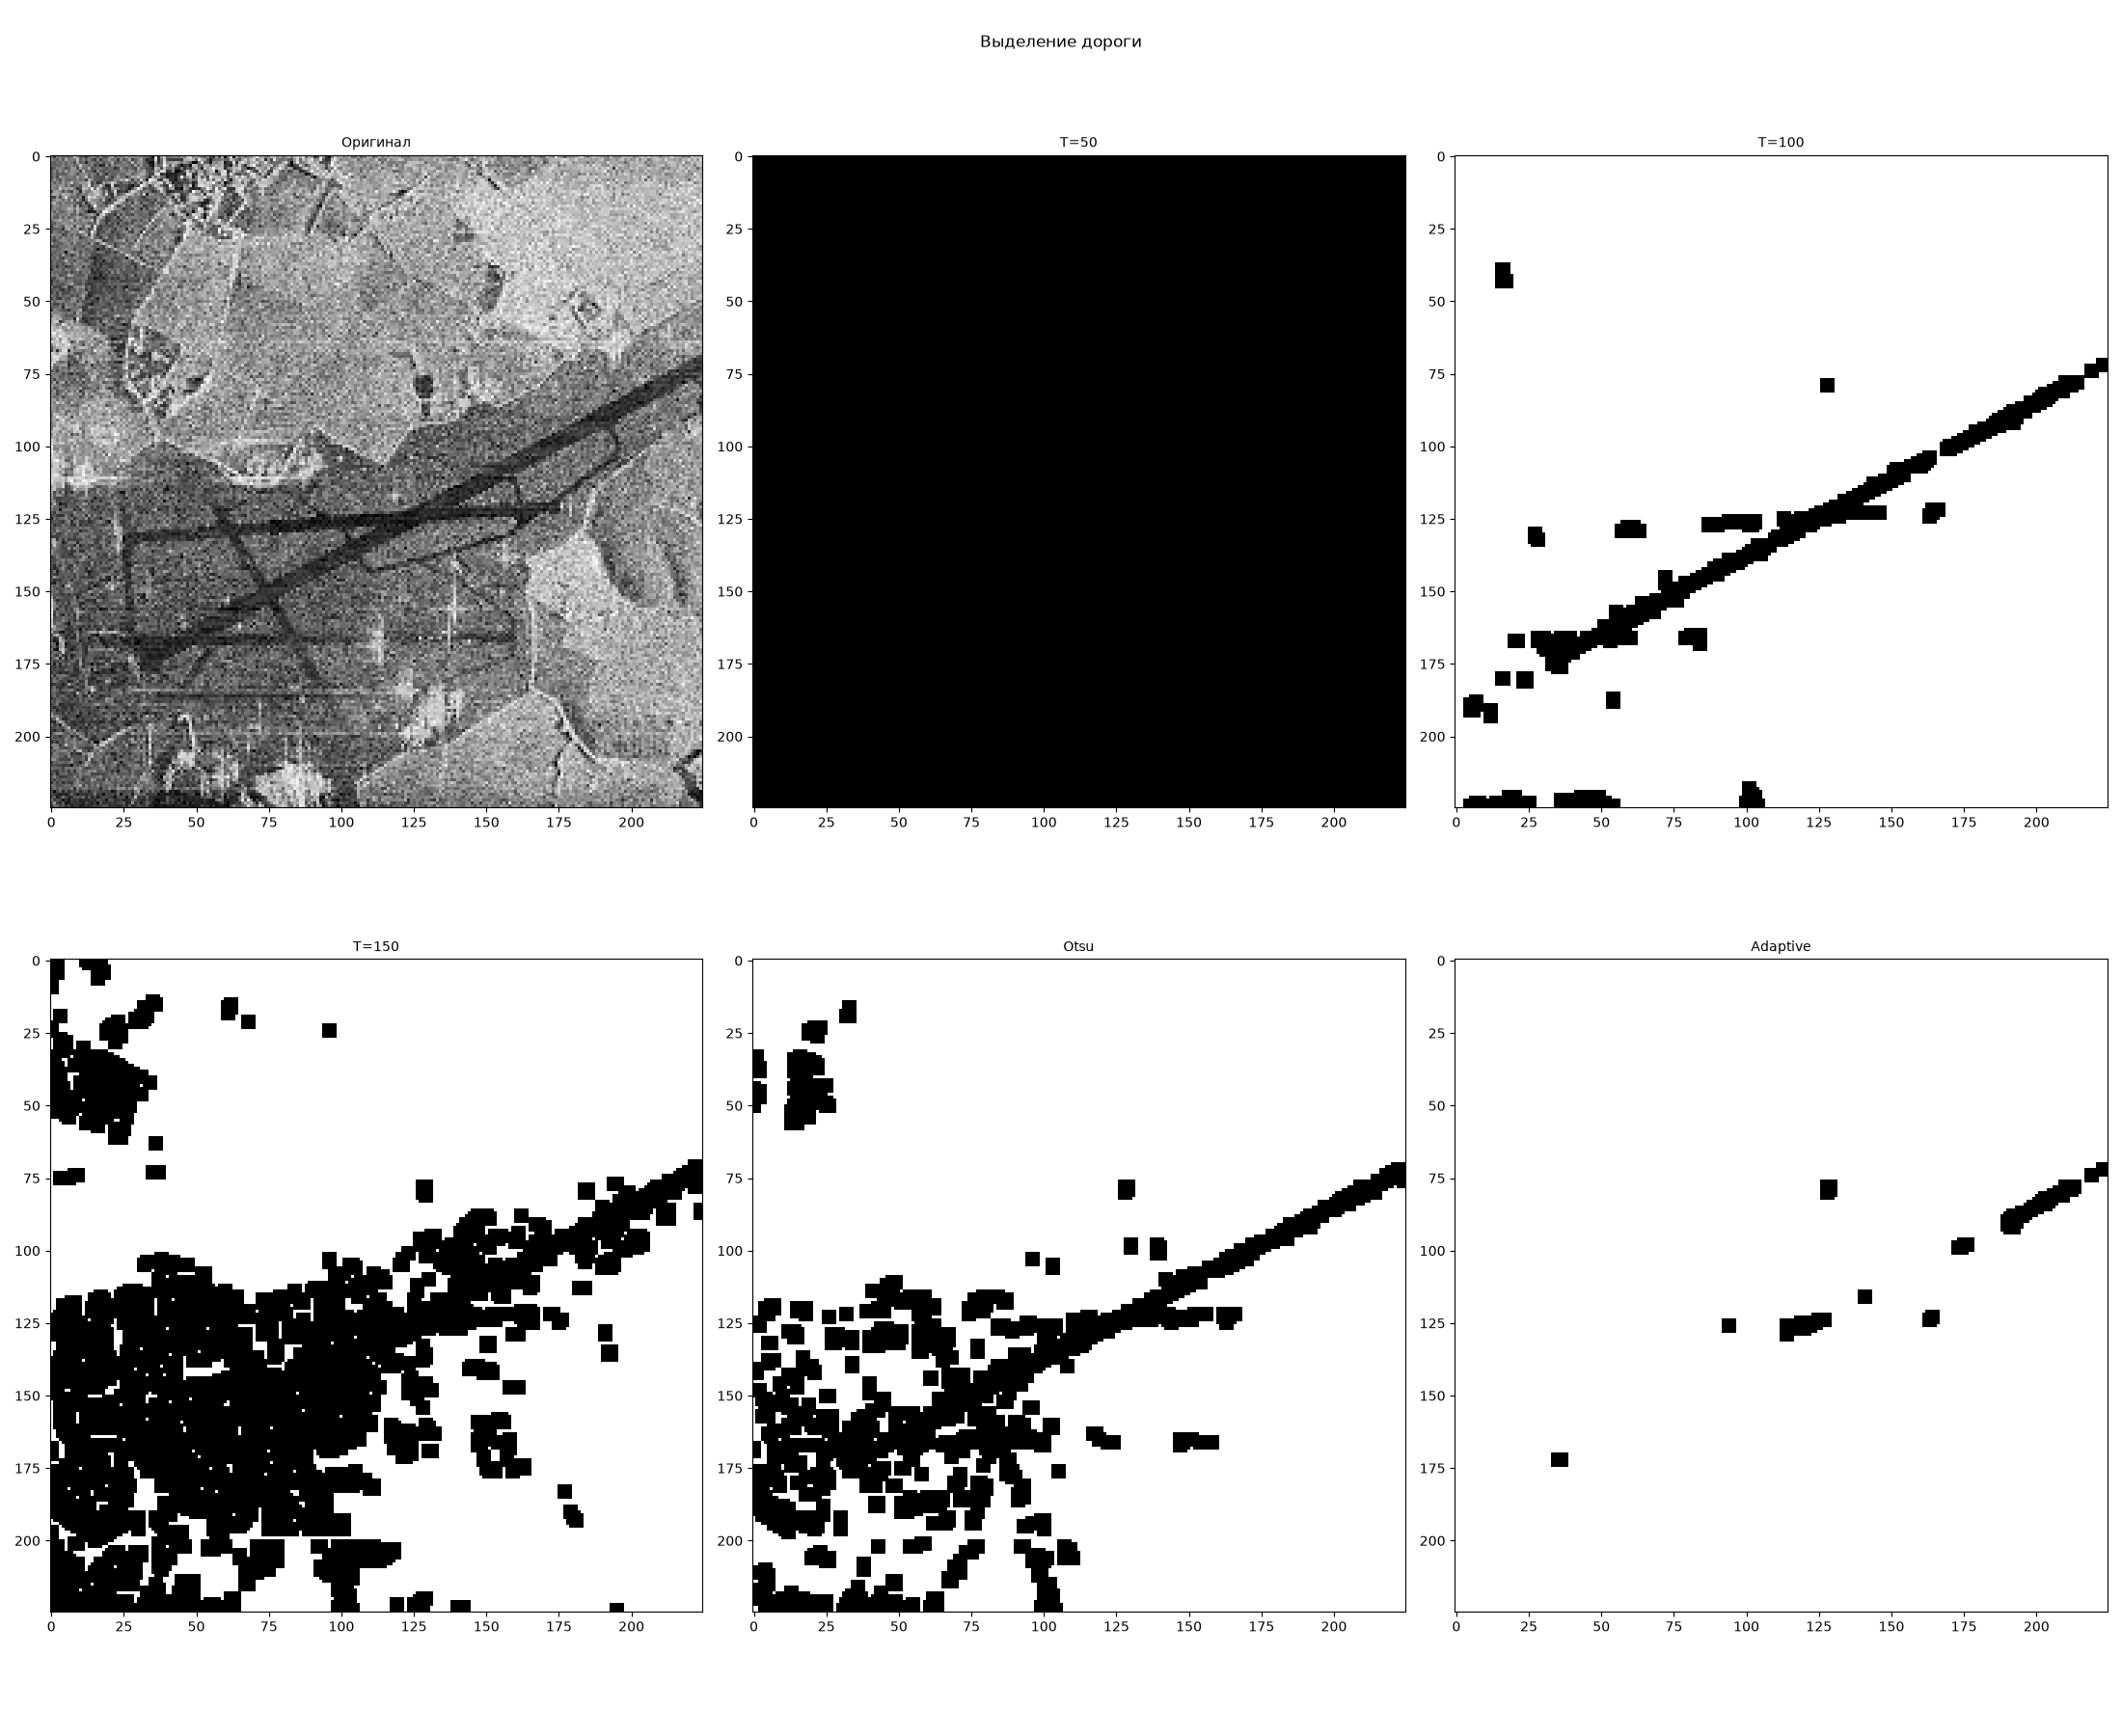

Выделение контура

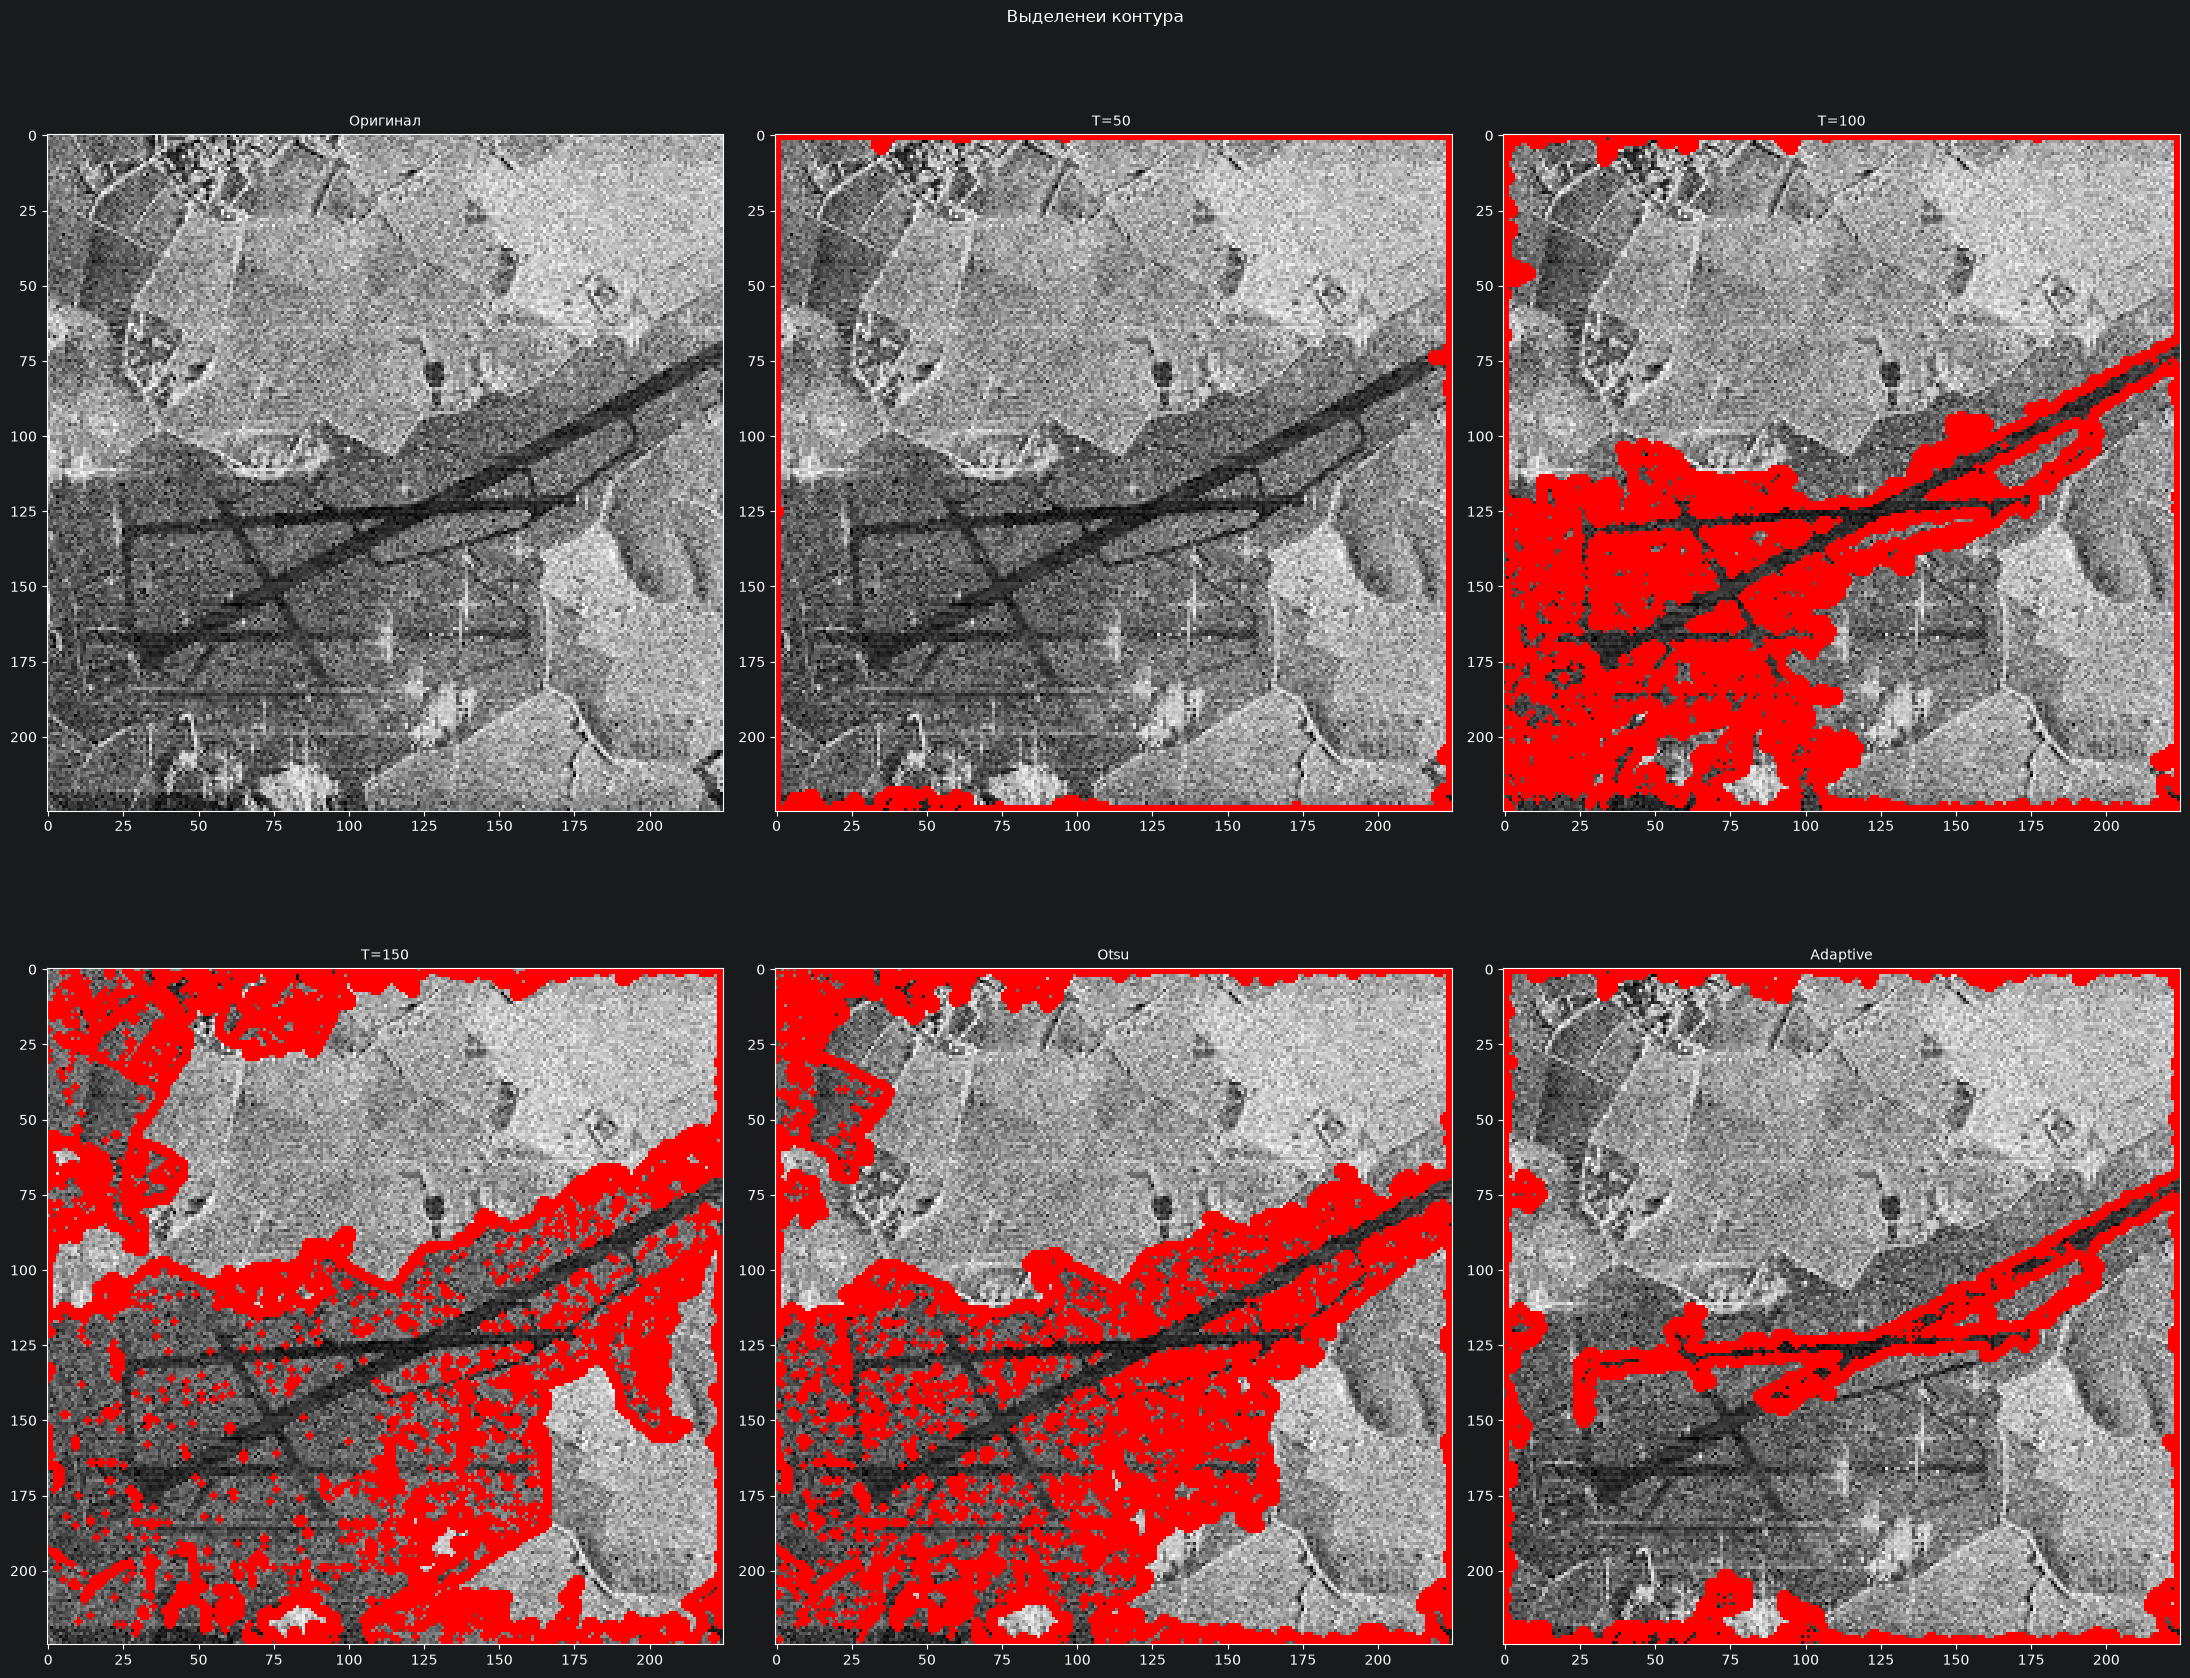

In [5]:
plt.figure(figsize=(22, 18))
plt.suptitle("Выделенеи контура", fontsize=12)


plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Оригинал", fontsize=10)
contours, _ = cv2.findContours(bin_manual_50, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_contours_50 = image.copy()
cv2.drawContours(img_contours_50, contours, -1, (255, 0, 0), 2)

plt.subplot(2, 3, 2)
plt.imshow(img_contours_50)
plt.title("T=50 ", fontsize=10)

contours, _ = cv2.findContours(bin_manual_100, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_contours_100 = image.copy()
cv2.drawContours(img_contours_100, contours, -1, (255, 0, 0), 2)
plt.subplot(2, 3, 3)
plt.imshow(img_contours_100)
plt.title("T=100", fontsize=10)

contours, _ = cv2.findContours(bin_manual_150, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_contours_150 = image.copy()
cv2.drawContours(img_contours_150, contours, -1, (255, 0, 0), 2)
plt.subplot(2, 3, 4)
plt.imshow(img_contours_150)
plt.title("T=150", fontsize=10)

contours, _ = cv2.findContours(bin_otsu, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_contours_otsu = image.copy()
cv2.drawContours(img_contours_otsu, contours, -1, (255, 0, 0), 2)
plt.subplot(2, 3, 5)
plt.imshow(img_contours_otsu)
plt.title("Otsu", fontsize=10)

contours, _ = cv2.findContours(bin_adaptive, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_contours_adapt = image.copy()
cv2.drawContours(img_contours_adapt, contours, -1, (255, 0, 0), 2)
plt.subplot(2, 3, 6)
plt.imshow(img_contours_adapt)
plt.title("Adaptive", fontsize=10)

plt.tight_layout()
plt.show()

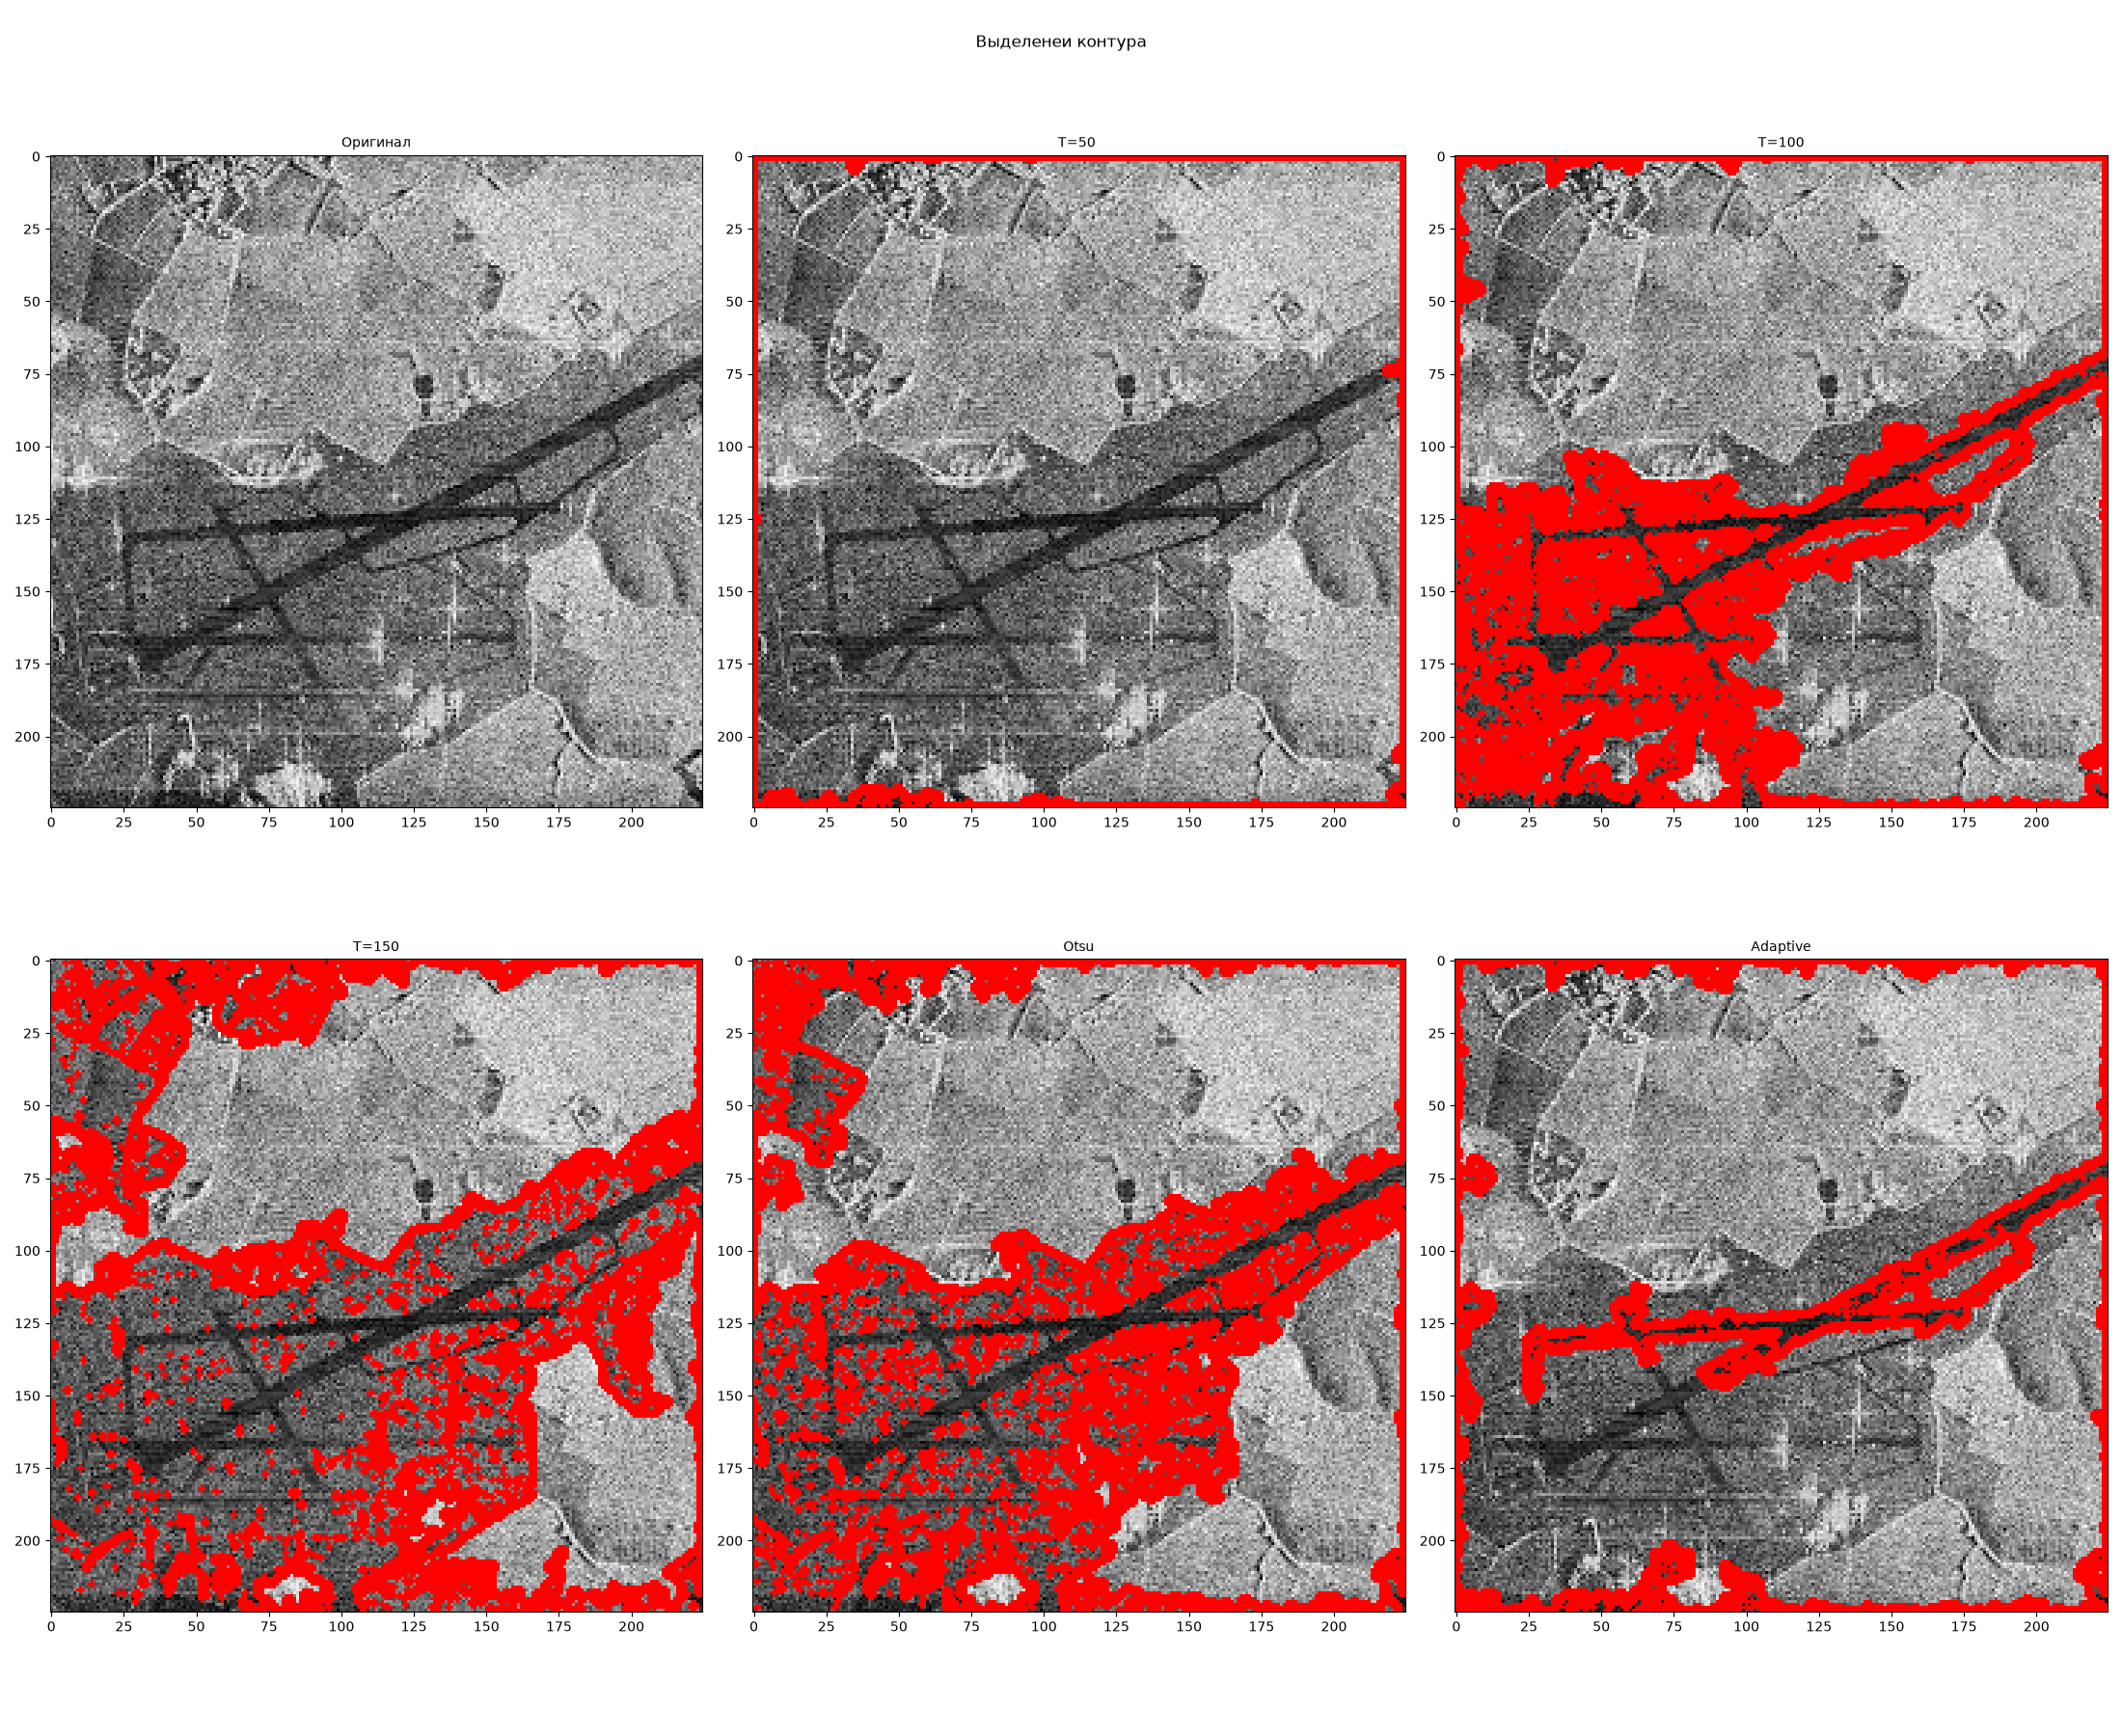